# Monotonic Architectures for Lost-Sales Inventory Control

This notebook checks the experiment against the project description: replace loss-function penalties for monotonicity with architectural enforcement, then evaluate whether the hard-monotone policy is better, faster, and more interpretable than penalty-based regularization without unacceptable reward loss.

The analysis is LS-first. Perishability, multi-echelon systems, and real-world demand are intentionally out of scope until the no-lead-time lost-sales baseline is credible.

## Mathematical Criteria

For inventory level `y` and order quantity policy `q(y)`, the lost-sales no-lead-time optimal structure is an order-up-to curve:

`q*(y) = max(S* - y, 0)`.

The core structural requirement is monotonicity:

`y_2 > y_1 => q(y_2) <= q(y_1)`.

This notebook reports:

- Reward ratio: `J(policy) / J(PaperFCNN) - 1`.
- Monotonicity violation rate: fraction of adjacent grid pairs with `q(y_{i+1}) > q(y_i)`.
- Slope deviation: mean `|dq/dy + 1|` where the order-up-to curve is active.
- Order-up-to error: `|q(0) - S*_omniscient|`, reported as MAE/RMSE.
- Speed ratio: `training_seconds(PaperFCNN) / training_seconds(policy)`, where larger is faster.

In [31]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "inventory_control").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from inventory_control.idp_benchmark import run_idp_benchmark

PROFILE = "auto"  # auto, compact, full, or paper_replication
if PROFILE == "auto":
    artifact_dir = ROOT / "outputs" / "idp_benchmark" / "structure-ls_full_validation"
    if not (artifact_dir / "summary.csv").exists():
        artifact_dir = ROOT / "outputs" / "idp_benchmark" / "structure-ls_compact_validation"
else:
    artifact_dir = ROOT / "outputs" / "idp_benchmark" / f"structure-ls_{PROFILE}_validation"

if not (artifact_dir / "summary.csv").exists():
    run_idp_benchmark(mode="structure-ls", profile="compact", split="validation", output_dir=artifact_dir)

summary = pd.read_csv(artifact_dir / "summary.csv")
table3 = pd.read_csv(artifact_dir / "paper_table3_replication.csv")
predictions = pd.read_csv(artifact_dir / "predictions.csv")
training = pd.read_csv(artifact_dir / "training_log.csv")
splines = pd.read_csv(artifact_dir / "monokan_splines.csv") if (artifact_dir / "monokan_splines.csv").exists() else pd.DataFrame()
notebook_plot_dir = ROOT / "outputs" / "notebook_plots"
notebook_plot_dir.mkdir(parents=True, exist_ok=True)

def show_plot(fig, name):
    path = notebook_plot_dir / f"{name}.png"
    fig.savefig(path, bbox_inches="tight", dpi=150)
    display(Image(filename=str(path)))
    plt.close(fig)

print(f"Loaded: {artifact_dir}")

Loaded: c:\Users\Apple\Desktop\IDP_Inventory_Control\outputs\idp_benchmark\structure-ls_compact_validation


## Plot Display Note

The committed notebook is intentionally output-free. Run the cells to render plots inline. The benchmark runner also saves static PNGs under `outputs/idp_benchmark/structure-ls_compact_validation/plots/`.

## Derived Comparison Metrics

The project objective requires a joint reading of reward, structure, training speed, and interpretability. A policy with perfect monotonicity but poor reward does not satisfy the project goal.

In [32]:
focus = ["PaperFCNN", "PenaltyMLP", "MonoKAN", "NonOmniscientOptimal", "OmniscientOptimal"]
comparison = summary[summary["policy_name"].isin(focus)].copy()
paper_reward = float(summary.loc[summary["policy_name"] == "PaperFCNN", "mean_reward_per_period"].iloc[0])
paper_seconds = float(summary.loc[summary["policy_name"] == "PaperFCNN", "training_seconds"].iloc[0])
comparison["reward_gap_vs_paper_fcnn_pct"] = 100.0 * (comparison["mean_reward_per_period"] / paper_reward - 1.0)
comparison["speedup_vs_paper_fcnn"] = paper_seconds / comparison["training_seconds"]
comparison.loc[comparison["training_seconds"].isna(), "speedup_vs_paper_fcnn"] = np.nan
comparison["passes_structure"] = comparison["raw_violation_rate"] == 0.0
comparison["passes_reward_tolerance"] = comparison["reward_gap_vs_paper_fcnn_pct"] >= -0.5
comparison["passes_project_goal"] = comparison["passes_structure"] & comparison["passes_reward_tolerance"]
comparison[[
    "policy_name",
    "mean_reward_per_period",
    "reward_gap_vs_paper_fcnn_pct",
    "raw_violation_rate",
    "mean_slope_deviation_from_minus_one",
    "order_up_to_mae",
    "training_seconds",
    "speedup_vs_paper_fcnn",
    "passes_project_goal",
]]

,policy_name,mean_reward_per_period,reward_gap_vs_paper_fcnn_pct,raw_violation_rate,mean_slope_deviation_from_minus_one,order_up_to_mae,training_seconds,speedup_vs_paper_fcnn,passes_project_goal
0,PaperFCNN,245.373965,0.000000,0.0,0.801917,6.411445,0.740902,1.000000,True
1,MonoKAN,132.405440,-46.039328,0.0,0.000000,31.827938,0.046268,16.013342,False
2,PenaltyMLP,245.373965,0.000000,0.0,0.801917,6.411445,0.090262,8.208323,True
3,NonOmniscientOptimal,197.570556,-19.481859,0.0,0.440709,1.438840,NaN,NaN,False
4,OmniscientOptimal,164.063594,-33.137326,0.0,0.386018,0.000000,NaN,NaN,False


In [33]:
def metric(policy, column):
    return float(summary.loc[summary["policy_name"] == policy, column].iloc[0])

if {"PaperFCNN", "MonoKAN", "PenaltyMLP"}.issubset(set(summary["policy_name"])):
    mono_reward_gap = 100.0 * (metric("MonoKAN", "mean_reward_per_period") / metric("PaperFCNN", "mean_reward_per_period") - 1.0)
    mono_speedup = metric("PaperFCNN", "training_seconds") / metric("MonoKAN", "training_seconds")
    penalty_reward_gap = 100.0 * (metric("PenaltyMLP", "mean_reward_per_period") / metric("PaperFCNN", "mean_reward_per_period") - 1.0)
    print("Mathematical interpretation")
    print(f"MonoKAN reward gap vs PaperFCNN: {mono_reward_gap:.2f}%")
    print(f"MonoKAN monotonicity violation rate: {metric('MonoKAN', 'raw_violation_rate'):.4f}")
    print(f"MonoKAN slope deviation from order-up-to slope -1: {metric('MonoKAN', 'mean_slope_deviation_from_minus_one'):.4f}")
    print(f"MonoKAN speedup vs PaperFCNN: {mono_speedup:.2f}x")
    print(f"PenaltyMLP reward gap vs PaperFCNN: {penalty_reward_gap:.2f}%")
    print(f"PenaltyMLP violation rate: {metric('PenaltyMLP', 'raw_violation_rate'):.4f}")
    print("Conclusion for this run:")
    if mono_reward_gap >= -0.5 and metric("MonoKAN", "raw_violation_rate") == 0.0:
        print("MonoKAN meets the project criterion: structure by construction without material reward loss.")
    else:
        print("MonoKAN does not yet meet the project criterion: structural quality is good, but reward must be improved before claiming success.")

Mathematical interpretation
MonoKAN reward gap vs PaperFCNN: -46.04%
MonoKAN monotonicity violation rate: 0.0000
MonoKAN slope deviation from order-up-to slope -1: 0.0000
MonoKAN speedup vs PaperFCNN: 16.01x
PenaltyMLP reward gap vs PaperFCNN: 0.00%
PenaltyMLP violation rate: 0.0000
Conclusion for this run:
MonoKAN does not yet meet the project criterion: structural quality is good, but reward must be improved before claiming success.


## Better, Faster, More Interpretable: Graphical Dashboard

This dashboard reads the project description directly: performance should not collapse, training speed is empirical, monotonicity should be exact for architectural models, and interpretability is measured through simple structural diagnostics.

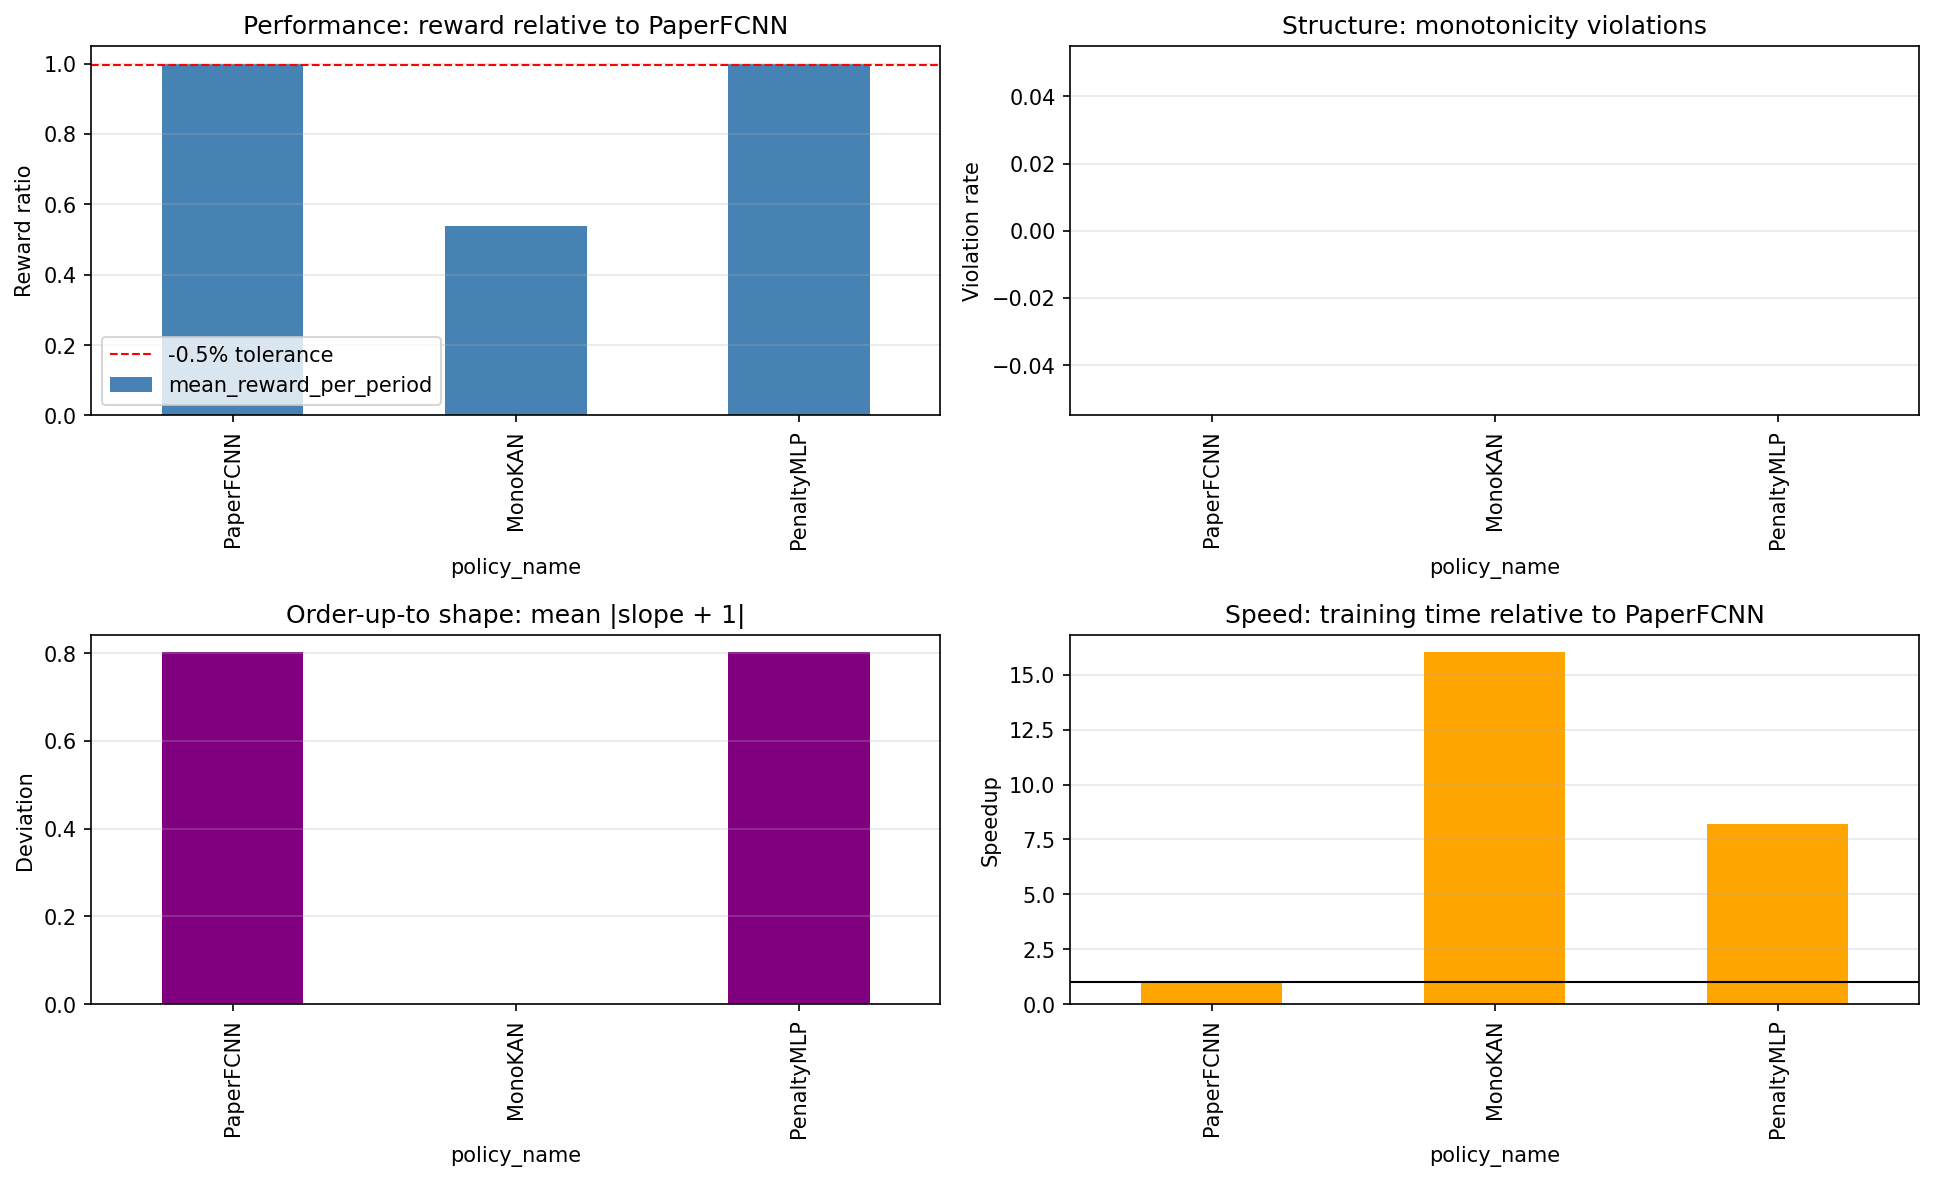

In [34]:
plot_policies = [p for p in ["PaperFCNN", "PenaltyMLP", "MonoKAN"] if p in set(summary["policy_name"])]
plot_df = comparison[comparison["policy_name"].isin(plot_policies)].set_index("policy_name")

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
(plot_df["mean_reward_per_period"] / paper_reward).plot.bar(ax=axes[0, 0], color="steelblue")
axes[0, 0].axhline(0.995, color="red", linestyle="--", linewidth=1, label="-0.5% tolerance")
axes[0, 0].set_title("Performance: reward relative to PaperFCNN")
axes[0, 0].set_ylabel("Reward ratio")
axes[0, 0].legend()

plot_df["raw_violation_rate"].plot.bar(ax=axes[0, 1], color="darkgreen")
axes[0, 1].set_title("Structure: monotonicity violations")
axes[0, 1].set_ylabel("Violation rate")

plot_df["mean_slope_deviation_from_minus_one"].plot.bar(ax=axes[1, 0], color="purple")
axes[1, 0].set_title("Order-up-to shape: mean |slope + 1|")
axes[1, 0].set_ylabel("Deviation")

plot_df["speedup_vs_paper_fcnn"].plot.bar(ax=axes[1, 1], color="orange")
axes[1, 1].axhline(1.0, color="black", linewidth=1)
axes[1, 1].set_title("Speed: training time relative to PaperFCNN")
axes[1, 1].set_ylabel("Speedup")

for ax in axes.flat:
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
show_plot(fig, "dashboard_better_faster_interpretable")

## Performance-Structure Tradeoff

The desired region is upper-left: high reward and low structural deviation. Hard monotonicity should move the model left without moving it far down.

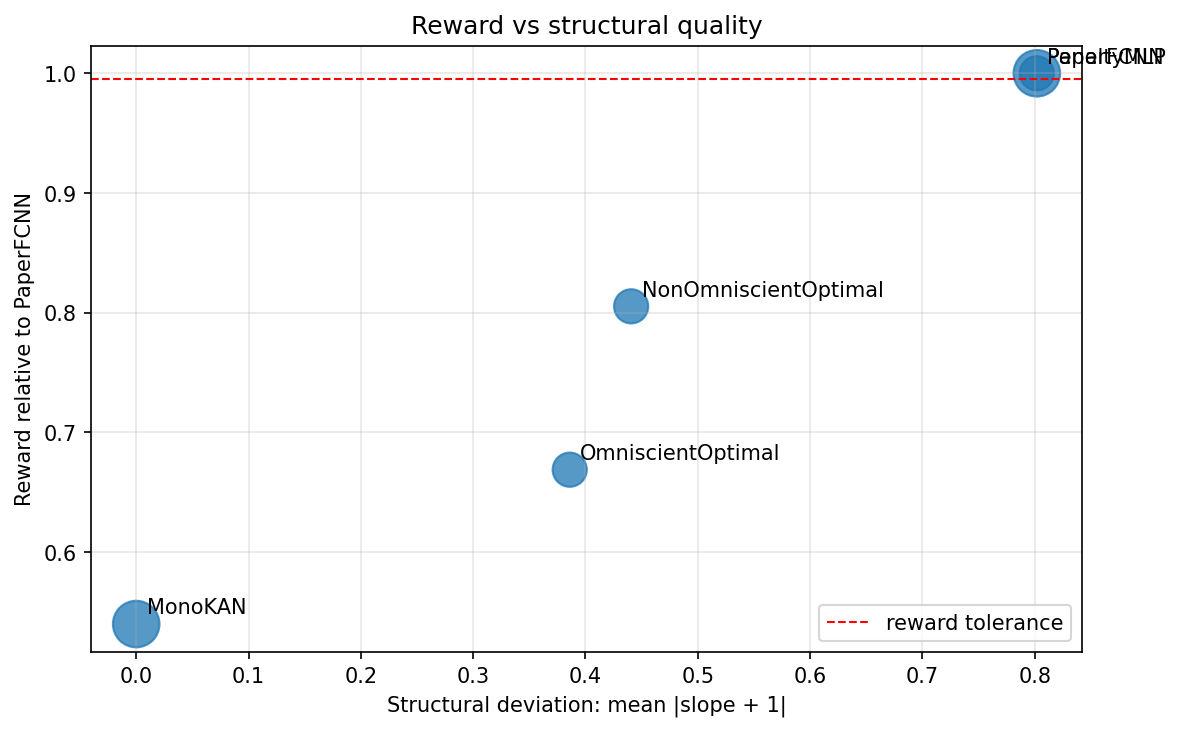

In [35]:
fig, ax = plt.subplots(figsize=(8, 5))
pareto = comparison[comparison["policy_name"].isin(["PaperFCNN", "PenaltyMLP", "MonoKAN", "NonOmniscientOptimal", "OmniscientOptimal"])]
x = pareto["mean_slope_deviation_from_minus_one"]
y = pareto["mean_reward_per_period"] / paper_reward
sizes = 200 / pareto["training_seconds"].fillna(pareto["training_seconds"].max()).replace(0, np.nan)
sizes = sizes.fillna(80).clip(lower=60, upper=500)
ax.scatter(x, y, s=sizes, alpha=0.75)
for _, row in pareto.iterrows():
    ax.annotate(row["policy_name"], (row["mean_slope_deviation_from_minus_one"], row["mean_reward_per_period"] / paper_reward), xytext=(5, 5), textcoords="offset points")
ax.axhline(0.995, color="red", linestyle="--", linewidth=1, label="reward tolerance")
ax.set_xlabel("Structural deviation: mean |slope + 1|")
ax.set_ylabel("Reward relative to PaperFCNN")
ax.set_title("Reward vs structural quality")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
show_plot(fig, "reward_structure_tradeoff")

## Policy Curves

The no-lead-time LS optimum is a piecewise linear order-up-to curve. The plots below inspect whether learned policies behave like `max(S-y,0)` on held-out products.

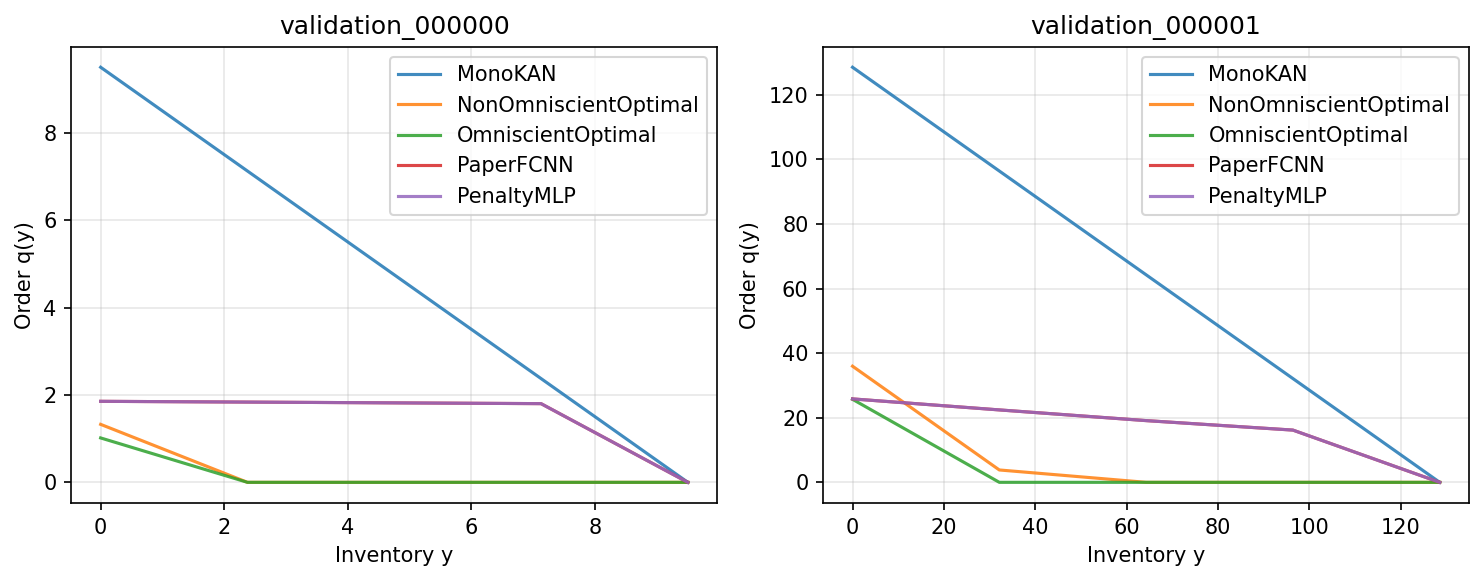

In [36]:
product_ids = predictions["product_id"].drop_duplicates().head(3).tolist()
curve_policies = {"PaperFCNN", "PenaltyMLP", "MonoKAN", "NonOmniscientOptimal", "OmniscientOptimal"}
fig, axes = plt.subplots(1, len(product_ids), figsize=(5 * len(product_ids), 4), squeeze=False)
for ax, product_id in zip(axes.flat, product_ids):
    rows_for_product = predictions[predictions["product_id"] == product_id]
    for policy, rows in rows_for_product.groupby("policy_name"):
        if policy not in curve_policies:
            continue
        rows.sort_values("inventory").plot(x="inventory", y="deployed_order", ax=ax, label=policy, alpha=0.85)
    ax.set_title(product_id)
    ax.set_xlabel("Inventory y")
    ax.set_ylabel("Order q(y)")
    ax.grid(alpha=0.3)
plt.tight_layout()
show_plot(fig, "policy_curves")

## Learned Order-Up-To Levels

At inventory `y=0`, an order-up-to policy reveals its target stock level: `q(0)=S`. Alignment with the omniscient `S*` is a structural accuracy diagnostic, not the primary training loss.

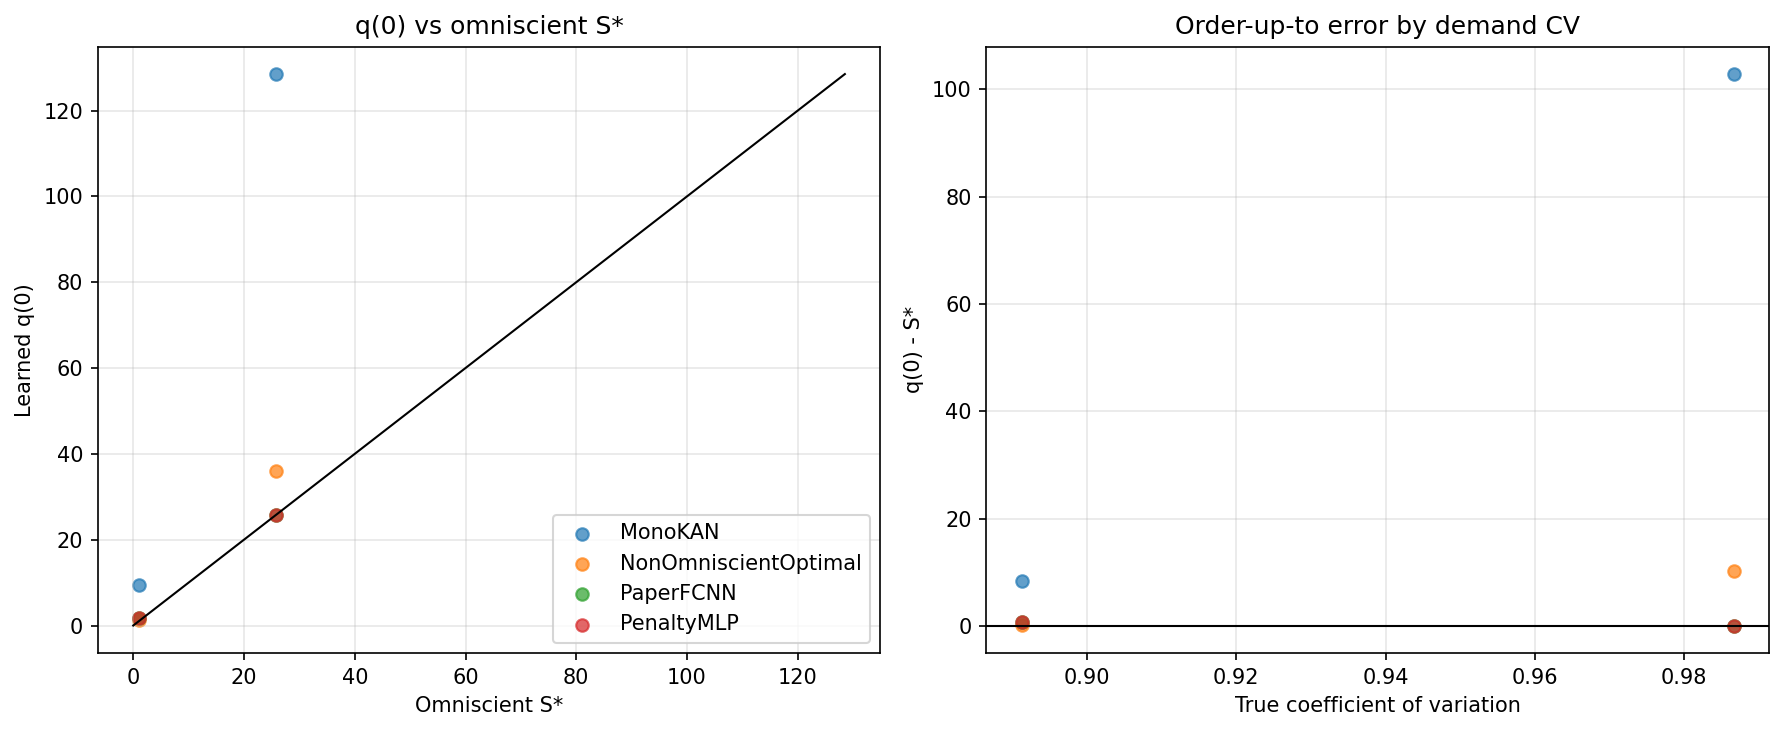

In [37]:
zero_inventory = predictions[predictions["state_index"] == 0]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for policy, rows in zero_inventory.groupby("policy_name"):
    if policy not in {"PaperFCNN", "PenaltyMLP", "MonoKAN", "NonOmniscientOptimal"}:
        continue
    axes[0].scatter(rows["omniscient_order_up_to_level"], rows["order_up_to_level"], label=policy, alpha=0.7)
limit = max(zero_inventory["omniscient_order_up_to_level"].max(), zero_inventory["order_up_to_level"].max())
axes[0].plot([0, limit], [0, limit], color="black", linewidth=1)
axes[0].set_title("q(0) vs omniscient S*")
axes[0].set_xlabel("Omniscient S*")
axes[0].set_ylabel("Learned q(0)")
axes[0].legend()
axes[0].grid(alpha=0.3)

for policy, rows in zero_inventory.groupby("policy_name"):
    if policy not in {"PaperFCNN", "PenaltyMLP", "MonoKAN", "NonOmniscientOptimal"}:
        continue
    axes[1].scatter(rows["true_coefficient_of_variation"], rows["order_up_to_level"] - rows["omniscient_order_up_to_level"], label=policy, alpha=0.7)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Order-up-to error by demand CV")
axes[1].set_xlabel("True coefficient of variation")
axes[1].set_ylabel("q(0) - S*")
axes[1].grid(alpha=0.3)
plt.tight_layout()
show_plot(fig, "order_up_to_diagnostics")

## Sample Efficiency and Learning Speed

Training speed is not guaranteed to improve under hard monotonicity. We inspect both wall-clock time and reward learning curves.

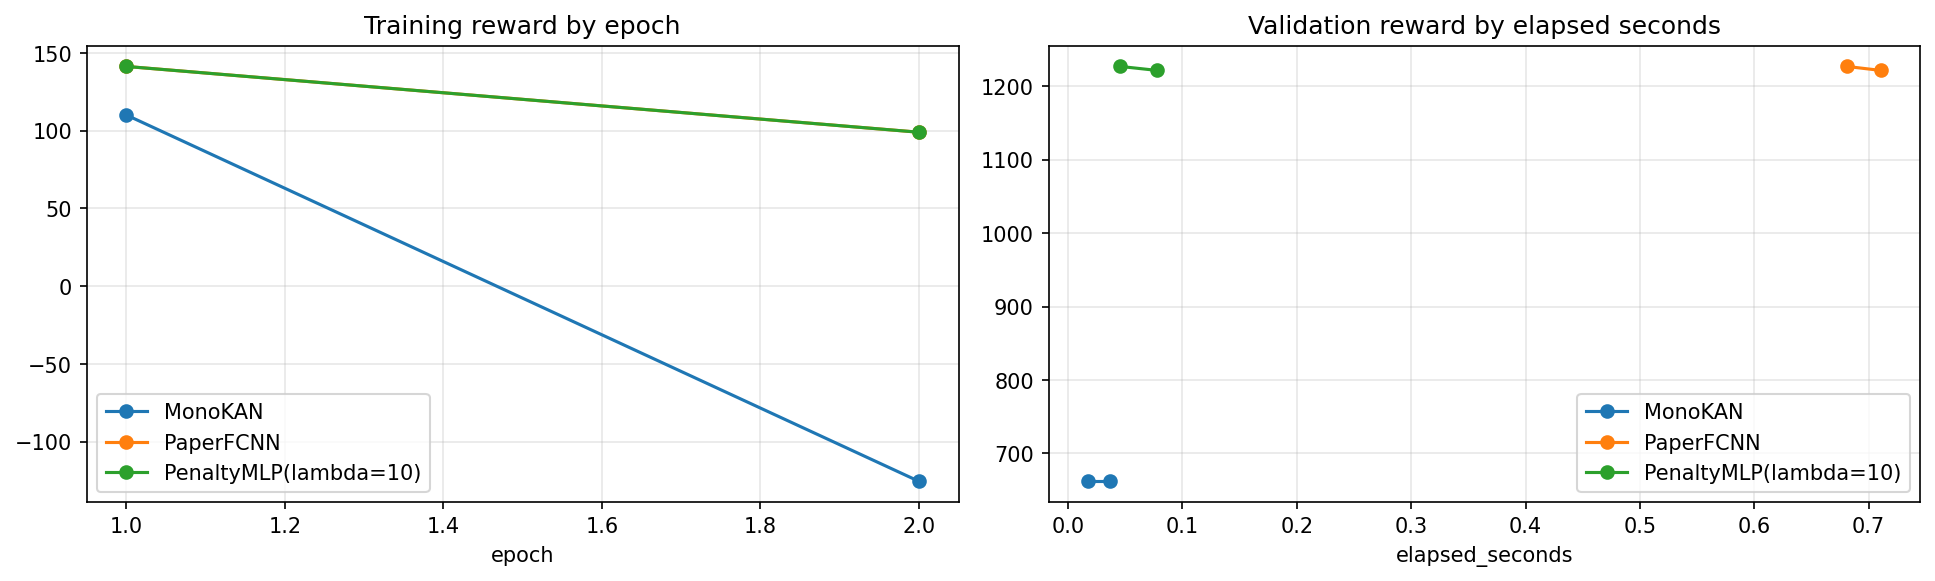

In [38]:
selected_training = training[training.get("selected", True) == True].copy()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for policy, rows in selected_training.groupby("policy_name"):
    rows.sort_values("epoch").plot(x="epoch", y="training_mean_total_reward", ax=axes[0], marker="o", label=policy)
    rows.dropna(subset=["validation_mean_total_reward"]).sort_values("elapsed_seconds").plot(x="elapsed_seconds", y="validation_mean_total_reward", ax=axes[1], marker="o", label=policy)
axes[0].set_title("Training reward by epoch")
axes[1].set_title("Validation reward by elapsed seconds")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
show_plot(fig, "training_curves")

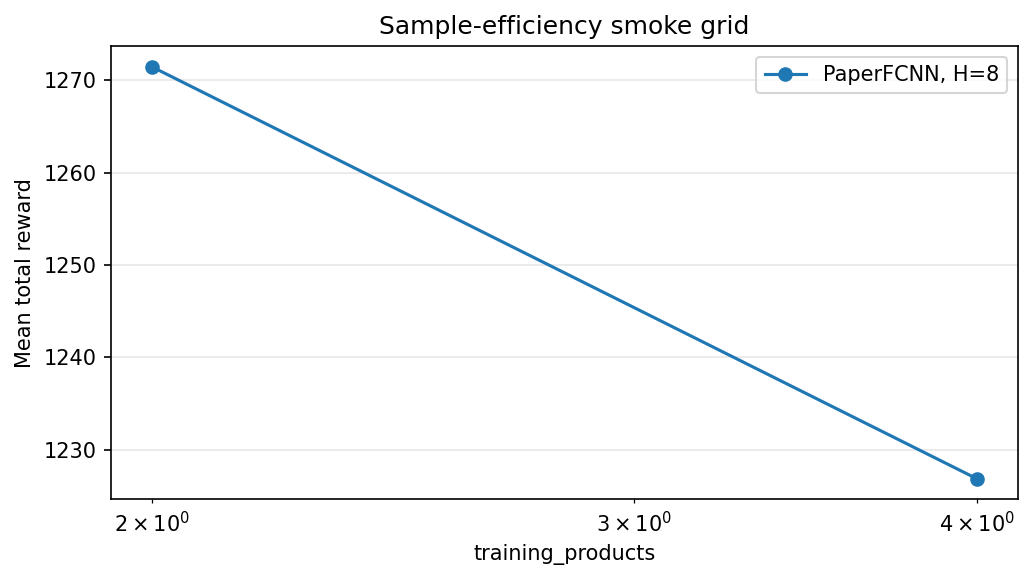

,history_window,training_products,policy_name,mean_total_reward,training_seconds
0,8,2,PaperFCNN,1271.426254,0.073693
1,8,4,PaperFCNN,1226.869826,0.108196


In [39]:
sample_dir = ROOT / "outputs" / "idp_benchmark" / "sample-efficiency_compact_validation"
if not (sample_dir / "sample_efficiency.csv").exists():
    run_idp_benchmark(mode="sample-efficiency", profile="compact", split="validation", output_dir=sample_dir)
sample_efficiency = pd.read_csv(sample_dir / "sample_efficiency.csv")
fig, ax = plt.subplots(figsize=(7, 4))
for (history, policy), rows in sample_efficiency.groupby(["history_window", "policy_name"]):
    rows.sort_values("training_products").plot(x="training_products", y="mean_total_reward", ax=ax, marker="o", label=f"{policy}, H={history}")
ax.set_xscale("log")
ax.set_title("Sample-efficiency smoke grid")
ax.set_ylabel("Mean total reward")
ax.grid(alpha=0.3)
plt.tight_layout()
show_plot(fig, "sample_efficiency")
sample_efficiency

## Interpretability: MonoKAN Spline Functions

MonoKAN is more interpretable because the first-layer inventory response is represented by explicit monotone spline edge functions. These plots expose the learned transformation instead of treating the policy as an opaque FCNN.

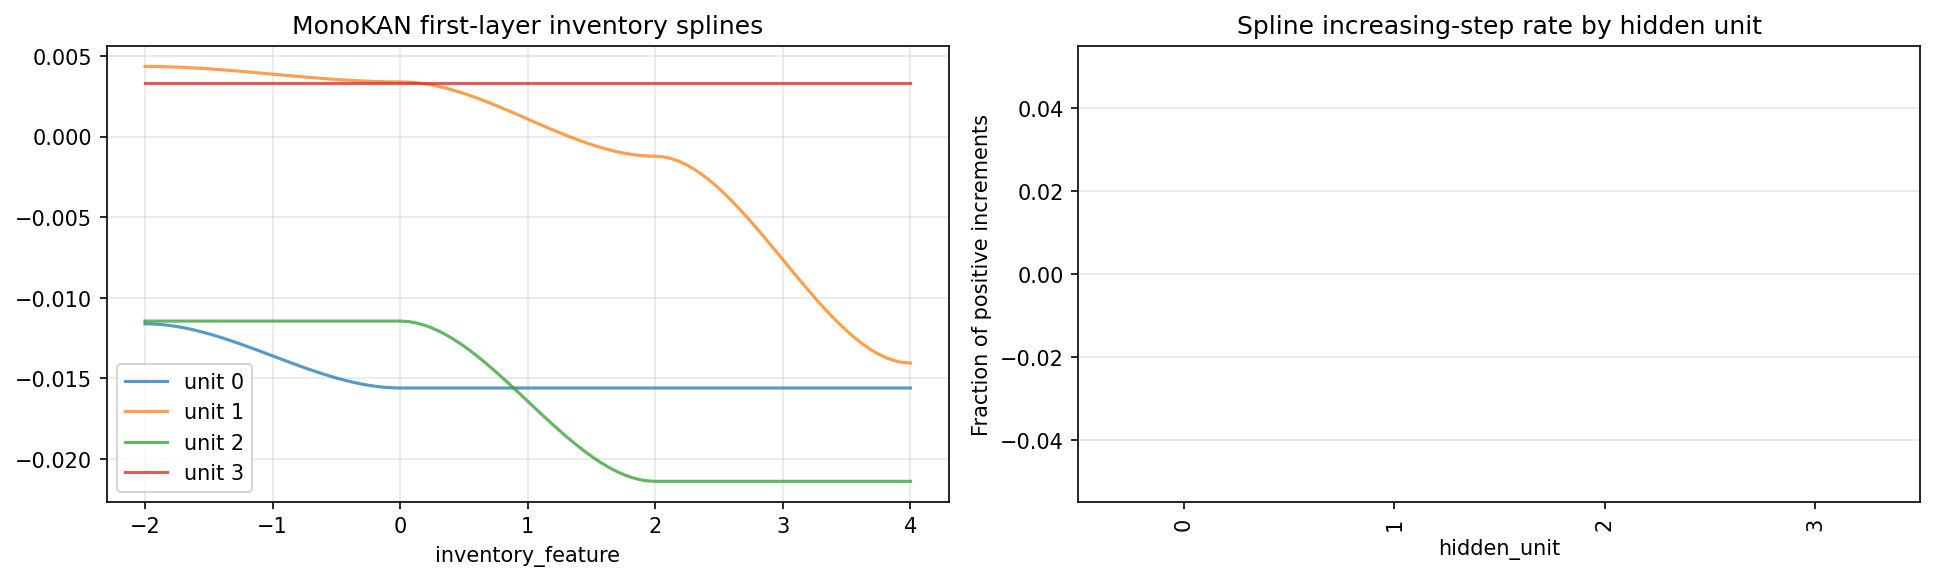

In [40]:
if not splines.empty:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for unit, rows in splines.groupby("hidden_unit"):
        rows.plot(x="inventory_feature", y="edge_value", ax=axes[0], label=f"unit {unit}", alpha=0.75)
    axes[0].set_title("MonoKAN first-layer inventory splines")
    axes[0].grid(alpha=0.3)
    if splines["hidden_unit"].nunique() > 8:
        axes[0].legend().remove()
    spline_pivot = splines.pivot(index="inventory_feature", columns="hidden_unit", values="edge_value")
    spline_slopes = spline_pivot.diff().dropna()
    (spline_slopes > 1e-8).mean().plot.bar(ax=axes[1], color="darkgreen")
    axes[1].set_title("Spline increasing-step rate by hidden unit")
    axes[1].set_ylabel("Fraction of positive increments")
    axes[1].grid(axis="y", alpha=0.3)
    plt.tight_layout()
    show_plot(fig, "monokan_splines")
else:
    print("No MonoKAN spline artifact for this mode.")

## Interpretation Summary

Read the current compact run as a development diagnostic, not a final scientific result. The mathematical decision rule is strict:

- If MonoKAN has zero violations and reward within tolerance of PaperFCNN, the architecture succeeds.
- If MonoKAN has zero violations but large reward loss, the architecture is structurally correct but under-tuned or too restrictive.
- If PenaltyMLP matches reward but does not improve structure, it is not sufficient for the project objective.

The final report should use `--profile paper_replication`; compact results are for smoke testing and notebook validation.